# 02 · Corrected analysis for the manuscript

Every number, table and figure in the manuscript comes from this notebook. It differs from the thesis analysis (notebook 01) in these ways:

| Issue in thesis | Correction here |
|---|---|
| Barrier models were fit with `event="2 No"` and the text for Tables 7-9 and Figures 3-4 read them backward | **Every outcome is coded 1 = access problem and every model uses `event=1`**, so OR > 1 always means *more* of the problem |
| "Insurance continuity" (`HINOTYR_A`) exists only for adults who are insured at interview | **Uninsured at interview** (`NOTCOV_A`) and **any coverage gap in the past 12 months** (uninsured at interview, or a lapse among the insured), both on the full adult sample |
| Tables 3-5 were proportional-odds models on insurance type / usual place | **Binary models:** uninsured, any gap, and *no usual place of care* |
| Income was a single imputation treated as observed | Primary analysis unchanged for comparability; **sensitivity analysis pools all 10 NCHS income imputations** (Rubin's rules) |
| No check that results are robust | Sensitivity analyses: insurance status as a covariate, imputed income, unweighted, collinearity; BH q-values for multiplicity |
| ORs only | Adjusted prevalences and risk differences (marginal standardization, delta-method CIs) |

Model: survey-weighted logistic regression, `WTFA_A` weight, `PSTRAT` strata, `PPSU` clusters, Taylor-linearized variance, t-based CIs with df = 610
(validated against the thesis SAS output in notebook 01). One mutually adjusted model per outcome with the same ten predictors and reference categories as the thesis.

In [1]:
import warnings, zipfile, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from nhis_survey import *
import plots
pd.set_option("display.width", 200, "display.max_columns", 40, "display.max_rows", 200, "display.float_format", "{:.3f}".format)

d = define_outcomes(recode(load_adult()))
KEEP = PREDICTORS + list(OUTCOMES) + ["INS_CAT", "WTFA_A", "PSTRAT", "PPSU", "HHX", "AGEP_A"]
ds = d[KEEP].copy()                                    # slim frame used for all models
SHORT = {k: v[0] for k, v in OUTCOMES.items()}
ORDER = list(OUTCOMES)
INS_OUT, BAR_OUT = ["UNINS", "ANYGAP", "NOUSUAL"], ["BAR_DELAY", "BAR_UNMET", "BAR_TRANSPORT", "BAR_RX"]

## 1 · Sample and outcome definitions

In [2]:
cc = ds.dropna(subset=PREDICTORS)
print(f"Sample adults in the 2024 NHIS file          : {len(ds):,}  (weighted {ds.WTFA_A.sum()/1e6:,.1f} million)")
print(f"Complete on all 10 predictors                : {len(cc):,}")
print("Missing by predictor:", {v: int(ds[v].isna().sum()) for v in PREDICTORS if ds[v].isna().any()})
print()
tab = pd.DataFrame({SHORT[k]: [int(ds[k].notna().sum()), int(ds[k].eq(1).sum()), int(ds[k].isna().sum()), int(cc[k].notna().sum())] for k in ORDER},
                   index=["nonmissing outcome", "events (outcome = 1)", "missing outcome", "analytic n (complete case)"]).T
display(tab)
print("\nCoding of the coverage-gap outcome (rows NOTCOV_A: 1 = uninsured, 2 = covered, 9 = don't know; cols HINOTYR_A):")
display(pd.crosstab(d.NOTCOV_A.fillna(-1).astype(int), d.HINOTYR_A.fillna(-1).astype(int), margins=True))

Sample adults in the 2024 NHIS file          : 32,629  (weighted 259.7 million)
Complete on all 10 predictors                : 31,076
Missing by predictor: {'FDSCAT4_A': 1351, 'HOUTENURE_A': 1384, 'SEX_A': 5, 'EDU_CAT': 147, 'PHSTAT_A': 16}



,nonmissing outcome,events (outcome = 1),missing outcome,analytic n (complete case)
Uninsured,32536,2318,93,31019
Any coverage gap,32488,3406,141,30980
No usual place,32390,2739,239,31044
Delayed care (cost),32355,2564,274,31057
Unmet care (cost),32354,2195,275,31061
Transportation,31222,1899,1407,31008
Unmet Rx (cost),32308,1953,321,31053



Coding of the coverage-gap outcome (rows NOTCOV_A: 1 = uninsured, 2 = covered, 9 = don't know; cols HINOTYR_A):


HINOTYR_A,-1,1,2,All
NOTCOV_A,,,,
1,2162,8,148,2318
2,48,1088,29082,30218
9,93,0,0,93
All,2303,1096,29230,32629


## 2 · Table 1: weighted sample description and outcome prevalence

In [3]:
dom = pd.Series(ds.index.isin(cc.index), index=ds.index)
rows = []
for v in PREDICTORS:
    for lev, lab in LEVEL_LABELS[v].items():
        flag = (ds[v] == lev).astype(float).where(ds[v].notna())
        pc = svy_prop(ds, flag, domain=dom)
        row = {"variable": v, "category": lab, "n": int((cc[v] == lev).sum()), "pct": 100 * pc["p"], "pct_lo": 100 * pc["lo"], "pct_hi": 100 * pc["hi"]}
        sub = dom & (ds[v] == lev)
        for k in ORDER:
            pr = svy_prop(ds, ds[k], domain=sub)
            row[k] = 100 * pr["p"]; row[k + "_lo"] = 100 * pr["lo"]; row[k + "_hi"] = 100 * pr["hi"]
        rows.append(row)
T1 = pd.DataFrame(rows)
T1.to_csv("results/table1_descriptives_long.csv", index=False)
# overall prevalence in the full sample (all adults with the outcome observed) and in the complete-case sample
overall = {k: svy_prop(ds, ds[k]) for k in ORDER}
overall_cc = {k: svy_prop(ds, ds[k], domain=dom) for k in ORDER}
display(Markdown("**Overall weighted prevalence (%, 95% CI), all adults with the outcome observed**"))
display(pd.DataFrame({SHORT[k]: [f"{100*o['p']:.1f} ({100*o['lo']:.1f}-{100*o['hi']:.1f})", o["n"]] for k, o in overall.items()}, index=["prevalence", "n"]).T)
show = T1[["variable", "category", "n", "pct"] + ORDER].rename(columns={**SHORT, "pct": "weighted %"})
display(show.set_index(["variable", "category"]))

**Overall weighted prevalence (%, 95% CI), all adults with the outcome observed**

,prevalence,n
Uninsured,9.1 (8.6-9.6),32536
Any coverage gap,13.0 (12.3-13.6),32488
No usual place,9.7 (9.2-10.2),32390
Delayed care (cost),8.6 (8.1-9.0),32355
Unmet care (cost),7.4 (7.0-7.8),32354
Transportation,6.1 (5.5-6.6),31222
Unmet Rx (cost),6.3 (6.0-6.7),32308


n  weighted %  Uninsured  Any coverage gap  No usual place  Delayed care (cost)  Unmet care (cost)  Transportation  Unmet Rx (cost)
variable    category                                                                                                                                                   
POV_CAT     <2 FPL               8698      27.047     17.262            22.844          13.025               11.620             10.758          12.438            9.868
            2-5 FPL             12836      41.489      8.478            12.589           9.757                9.759              8.142           4.582            6.455
            >5 FPL               9542      31.464      2.689             4.649           6.391                4.356              3.326           2.598            2.895
FDSCAT4_A   High                26392      83.774      7.403            10.457           8.582                5.938              4.778           3.618            4.083
            Marginal             1947       6.884     14.788            20.841          13.811               15.789             13.800          13.049           11.097
            Low                  1561       5.599     19.247            27.263          14.360               22.433             22.300          17.188           16.687
            Very low             1176       3.743     19.506            30.358          17.039               33.244             30.241          31.695           30.403
HOUTENURE_A Owned               21083      69.732      6.331             9.039           6.902                6.857              5.764           4.222            5.065
            Rented               9383      28.539     15.436            21.890          15.882               12.549             10.964          10.281            8.832
            Other                 610       1.729     12.189            17.989          13.801               11.605             10.784          11.591           11.871
REGION      Northeast            4836      17.027      5.853             8.795           6.066                6.088              5.203           4.756            3.993
            Midwest              7236      20.803      7.280            10.685           8.291                8.404              6.839           5.543            5.819
            South               11247      38.639     12.195            16.463          11.412               10.071              8.763           7.201            7.970
            West                 7757      23.531      7.662            11.766          10.259                8.015              6.969           5.655            5.472
URBRRL23    Large central        8857      31.466      9.649            13.727          11.545                8.123              7.135           5.821            5.774
            Large fringe         6472      24.781      7.401            10.749           8.367                7.852              6.563           4.874            5.212
            Medium/small metro   8699      29.457      9.446            13.549           9.766                9.846              8.155           7.426            7.277
            Nonmetropolitan      7048      14.297      9.615            13.133           6.983                8.117              7.422           5.946            7.036
SEX_A       Male                14272      48.660     10.220            13.876          12.740                7.469              6.517           5.814            4.793
            Female              16804      51.340      7.899            11.883           6.588                9.598              8.109           6.326            7.646
EDU_CAT     Less than HS         2520      10.247     22.428            27.396          14.915                9.796              9.584          12.643            8.903
            High School          7972      26.828     12.746            17.027          11.718                8.655              7.584           6.781            6.359
    

## 3 · Primary models (one adjusted model per outcome, `event=1`)

In [4]:
fits, prim, rows = {}, {}, []
for k in ORDER:
    r, i = svy_logit(ds, k, 1)
    fits[k] = (r, i)
    r = r.copy(); r["q_BH"] = np.nan
    mask = r["var"] != "const"
    r.loc[mask, "q_BH"] = bh_qvalues(r.loc[mask, "p"].values)
    prim[k] = plots._clean(r)
    out = prim[k].copy(); out.insert(0, "outcome", k); rows.append(out)
    print(f"{k:14s} n={i['n']:6,d}  events={i['n_events']:5,d}  df={i['df']}  PSUs={i['n_psu']}  strata={i['n_strata']}")
long = pd.concat(rows)
long["label"] = [f"{v}: {plots.LEVEL_LABELS[v][l]} vs {plots.LEVEL_LABELS[v][r]}" for v, l, r in zip(long["var"], long["level"], long["ref"])]  # code-based labels (stable keys for downstream scripts)
long.to_csv("results/primary_models_long.csv", index=False)
sig = pd.DataFrame({SHORT[k]: [int((prim[k].p < .05).sum()), int((prim[k].q_BH < .05).sum()), len(prim[k])] for k in ORDER},
                   index=["significant, p<0.05", "significant, BH q<0.05", "coefficients tested"]).T
display(sig)

UNINS          n=31,019  events=2,183  df=610  PSUs=662  strata=52


ANYGAP         n=30,980  events=3,216  df=610  PSUs=662  strata=52


NOUSUAL        n=31,044  events=2,593  df=610  PSUs=662  strata=52


BAR_DELAY      n=31,057  events=2,452  df=610  PSUs=662  strata=52


BAR_UNMET      n=31,061  events=2,090  df=610  PSUs=662  strata=52


BAR_TRANSPORT  n=31,008  events=1,885  df=610  PSUs=662  strata=52


BAR_RX         n=31,053  events=1,865  df=610  PSUs=662  strata=52


,"significant, p<0.05","significant, BH q<0.05",coefficients tested
Uninsured,18,17,29
Any coverage gap,17,16,29
No usual place,23,22,29
Delayed care (cost),23,23,29
Unmet care (cost),19,18,29
Transportation,16,14,29
Unmet Rx (cost),16,15,29


In [5]:
# Table 2 (manuscript layout): adjusted OR (95% CI), * = p < 0.05
def cell(r): return f"{r.OR:.2f} ({r.lo:.2f}-{r.hi:.2f})" + ("*" if r.p < 0.05 else "")
idx = [(v, f"{LEVEL_LABELS[v][l]} vs {LEVEL_LABELS[v][r]}") for v, l, r in zip(prim[ORDER[0]]["var"], prim[ORDER[0]]["level"], prim[ORDER[0]]["ref"])]
T2 = pd.DataFrame({SHORT[k]: [cell(r) for r in prim[k].itertuples()] for k in ORDER}, index=pd.MultiIndex.from_tuples(idx, names=["variable", "contrast"]))
T2.to_csv("results/table2_adjusted_ORs.csv")
display(T2)

Uninsured   Any coverage gap     No usual place Delayed care (cost)  Unmet care (cost)     Transportation    Unmet Rx (cost)
variable    contrast                                                                                                                                                                 
POV_CAT     2-5 FPL vs <2 FPL                    0.70 (0.60-0.81)*  0.75 (0.66-0.86)*   0.93 (0.82-1.07)   1.30 (1.13-1.50)*  1.25 (1.08-1.45)*  0.62 (0.52-0.73)*   1.10 (0.95-1.28)
            >5 FPL vs <2 FPL                     0.30 (0.24-0.38)*  0.35 (0.29-0.41)*  0.68 (0.57-0.80)*   0.68 (0.56-0.82)*  0.64 (0.52-0.80)*  0.50 (0.39-0.65)*  0.67 (0.53-0.83)*
FDSCAT4_A   Marginal vs High                      1.09 (0.90-1.32)  1.18 (1.01-1.39)*  1.26 (1.04-1.53)*   2.19 (1.84-2.61)*  2.24 (1.86-2.69)*  2.63 (2.03-3.40)*  2.09 (1.73-2.53)*
            Low vs High                          1.34 (1.08-1.67)*  1.55 (1.28-1.87)*  1.28 (1.02-1.59)*   3.41 (2.85-4.07)*  3.99 (3.32-4.81)*  3.16 (2.56-3.90)*  3.07 (2.51-3.75)*
            Very low vs High                     1.45 (1.15-1.84)*  1.84 (1.51-2.25)*  1.56 (1.24-1.97)*   5.28 (4.36-6.41)*  5.47 (4.47-6.69)*  6.70 (5.36-8.39)*  6.46 (5.22-7.99)*
HOUTENURE_A Rented vs Owned                      1.35 (1.18-1.54)*  1.42 (1.27-1.58)*  1.67 (1.48-1.89)*   1.23 (1.09-1.40)*  1.19 (1.04-1.36)*  1.39 (1.20-1.60)*   1.11 (0.96-1.28)
            Other vs Owned                        1.35 (0.92-1.97)   1.40 (0.98-2.01)  1.89 (1.36-2.62)*    1.14 (0.78-1.68)   1.18 (0.80-1.74)  1.64 (1.10-2.44)*  1.52 (1.03-2.26)*
REGION      Northeast vs South                   0.52 (0.41-0.66)*  0.56 (0.46-0.68)*  0.50 (0.40-0.61)*   0.62 (0.52-0.75)*  0.64 (0.53-0.77)*  0.77 (0.59-0.99)*  0.54 (0.44-0.66)*
            Midwest vs South                     0.70 (0.59-0.82)*  0.72 (0.62-0.83)*  0.75 (0.64-0.89)*   0.81 (0.69-0.95)*  0.78 (0.66-0.92)*   0.89 (0.66-1.18)  0.74 (0.63-0.88)*
            West vs South                        0.51 (0.43-0.60)*  0.61 (0.52-0.72)*  0.75 (0.64-0.88)*   0.81 (0.70-0.94)*  0.81 (0.69-0.96)*   0.91 (0.71-1.16)  0.75 (0.64-0.88)*
URBRRL23    Large fringe vs Large central         1.01 (0.84-1.21)   1.00 (0.86-1.17)   0.86 (0.73-1.03)    1.05 (0.89-1.24)   1.02 (0.85-1.22)   0.99 (0.80-1.23)   0.96 (0.78-1.17)
            Medium/small metro vs Large central   1.13 (0.95-1.35)   1.11 (0.95-1.30)   0.93 (0.79-1.10)    1.12 (0.97-1.30)   1.06 (0.90-1.25)   1.25 (0.97-1.62)   1.12 (0.95-1.31)
            Nonmetropolitan vs Large central      1.13 (0.92-1.37)   1.06 (0.90-1.25)  0.65 (0.53-0.81)*   0.83 (0.70-0.99)*   0.89 (0.74-1.08)   0.83 (0.65-1.07)   0.97 (0.79-1.18)
SEX_A       Female vs Male                       0.72 (0.64-0.81)*  0.80 (0.72-0.88)*  0.47 (0.42-0.52)*   1.20 (1.07-1.34)*  1.13 (1.01-1.28)*   0.94 (0.82-1.07)  1.49 (1.32-1.68)*
EDU_CAT     High School vs Less than HS          0.62 (0.51-0.74)*  0.64 (0.54-0.75)*  0.81 (0.67-0.98)*    1.00 (0.81-1.23)   0.92 (0.74-1.14)  0.62 (0.51-0.76)*   0.82 (0.66-1.02)
            Some College vs Less than HS         0.41 (0.34-0.50)*  0.47 (0.40-0.56)*  0.61 (0.49-0.75)*   1.33 (1.08-1.63)*  1.29 (1.05-1.58)*  0.66 (0.53-0.80)*   1.14 (0.92-1.42)
            Bachelor+ vs Less than HS            0.27 (0.22-0.34)*  0.37 (0.31-0.45)*  0.61 (0.49-0.75)*   1.46 (1.19-1.80)*   1.17 (0.95-1.45)  0.65 (0.50-0.83)*   1.07 (0.85-1.34)
RACE_CAT    Hispanic vs White                    2.61 (2.22-3.08)*  2.13 (1.86-2.45)*  1.27 (1.10-1.47)*   0.82 (0.70-0.96)*   0.93 (0.79-1.10)  0.80 (0.65-0.98)*  0.80 (0.66-0.97)*
            Black vs White                        0.84 (0.66-1.06)   0.91 (0.76-1.10)  0.68 (0.55-0.85)*   0.58 (0.48-0.71)*  0.65 (0.53-0.80)*   1.07 (0.87-1.31)   0.88 (0.72-1.08)
            Asian vs White                        0.98 (0.71-1.37)   0.92 (0.72-1.17)   1.21 (0.96-1.51)   0.41 (0.31-0.55)*  0.54 (0.39-0.75)*   0.89 (0.63-1.25)  0.56 (0.38-0.82)*
            AIAN vs White                         1.2

## 4 · Figures

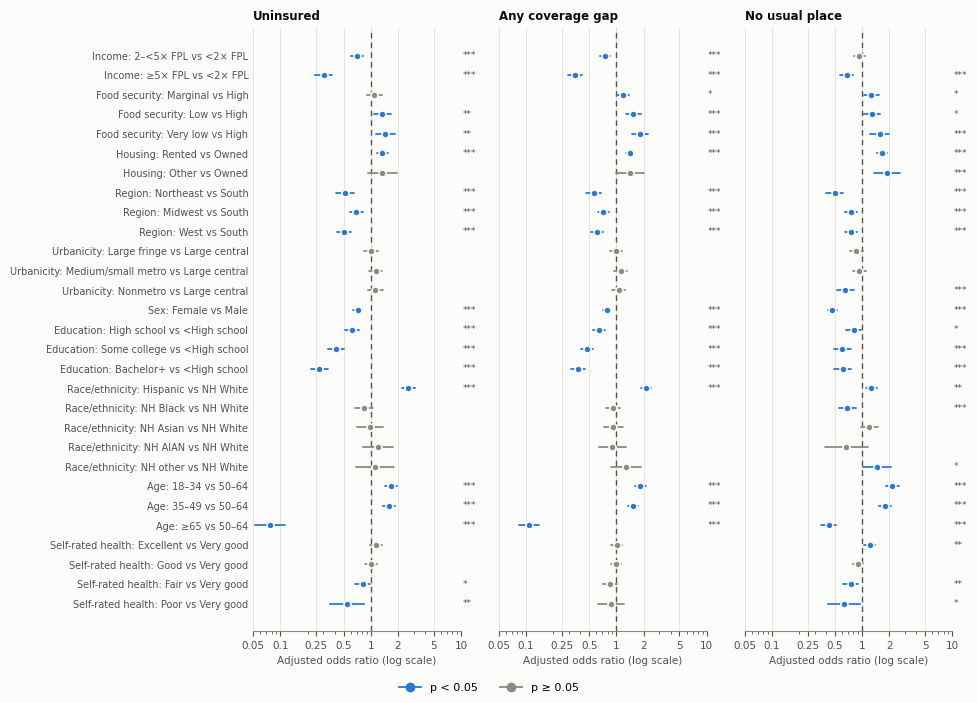

In [6]:
xl = plots.auto_xlim([prim[k] for k in INS_OUT])
plots.forest_panels({k: prim[k] for k in INS_OUT}, SHORT, ncols=3, xlim=xl, figsize=(9.8, 7.0),
                    suptitle="Adjusted odds of insurance and usual-source-of-care problems (OR > 1 = more of the problem)",
                    xlabel="Adjusted odds ratio (log scale)", outfile="figures/fig2_forest_insurance_usual_place.png"); plt.show()

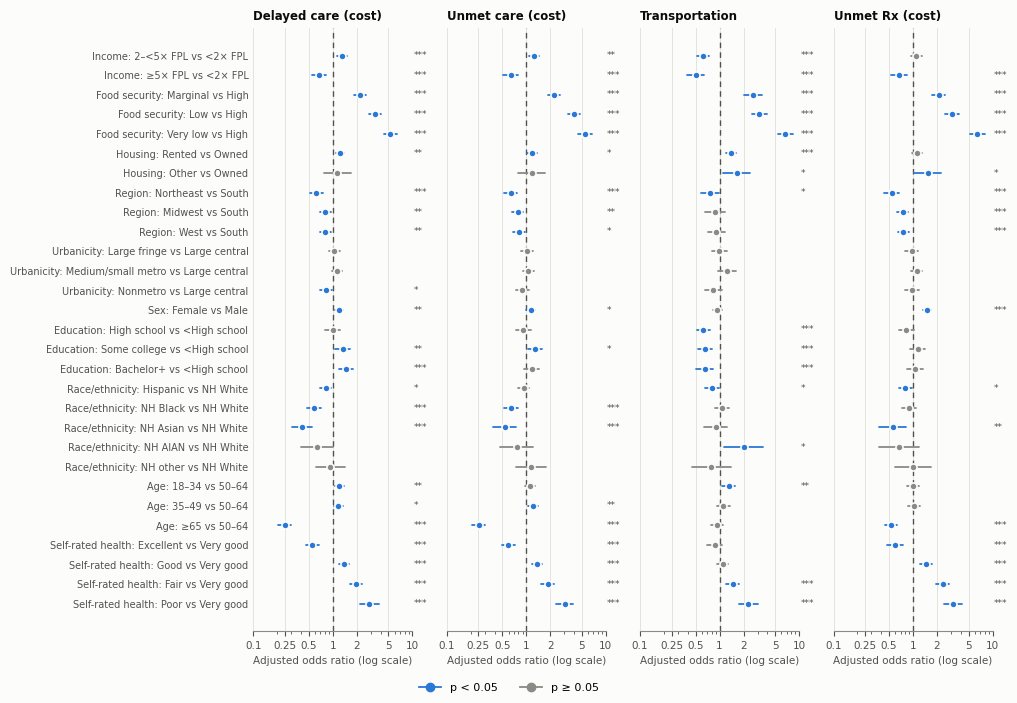

In [7]:
xl = plots.auto_xlim([prim[k] for k in BAR_OUT])
plots.forest_panels({k: prim[k] for k in BAR_OUT}, SHORT, ncols=4, xlim=xl, figsize=(10.2, 7.0),
                    suptitle="Adjusted odds of cost and transportation barriers to care (OR > 1 = more barrier)",
                    xlabel="Adjusted odds ratio (log scale)", outfile="figures/fig3_forest_barriers.png"); plt.show()

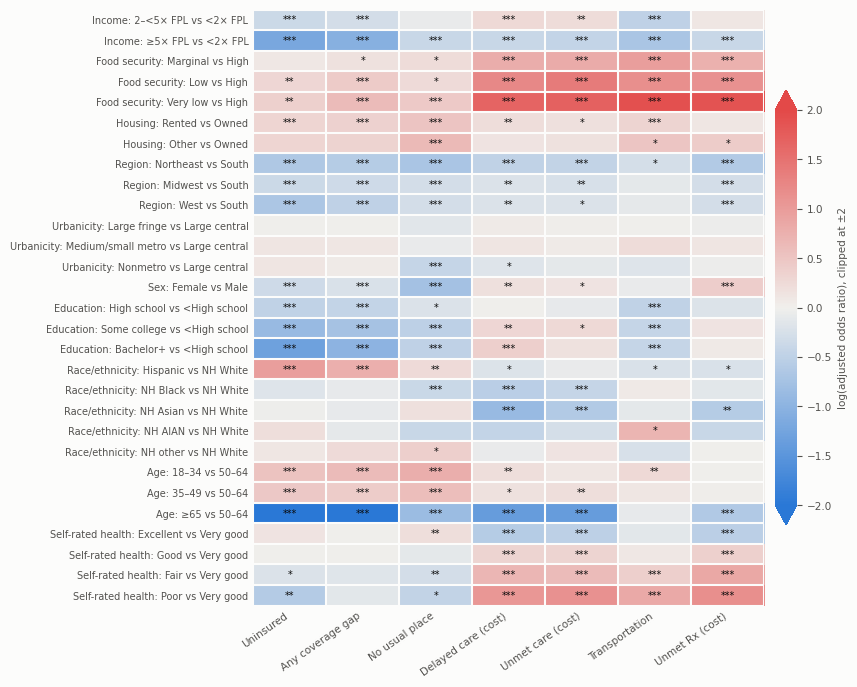

heatmap color limit = +/- 2.0


In [8]:
vmax = 2.0      # color scale clipped at +/-2 (OR 0.14-7.4) so moderate effects stay visible; larger values (65+ vs 50-64, uninsured) saturate
plots.heatmap({k: prim[k] for k in ORDER}, SHORT, vlim=vmax, figsize=(8.6, 6.9),
              suptitle="Adjusted association with each access problem: log(OR); red = more of the problem",
              cbar_label="log(adjusted odds ratio), clipped at \u00b12", outfile="figures/fig4_heatmap_all_outcomes.png"); plt.show()
print("heatmap color limit = +/-", vmax)

## 5 · Adjusted prevalences and risk differences (marginal standardization)

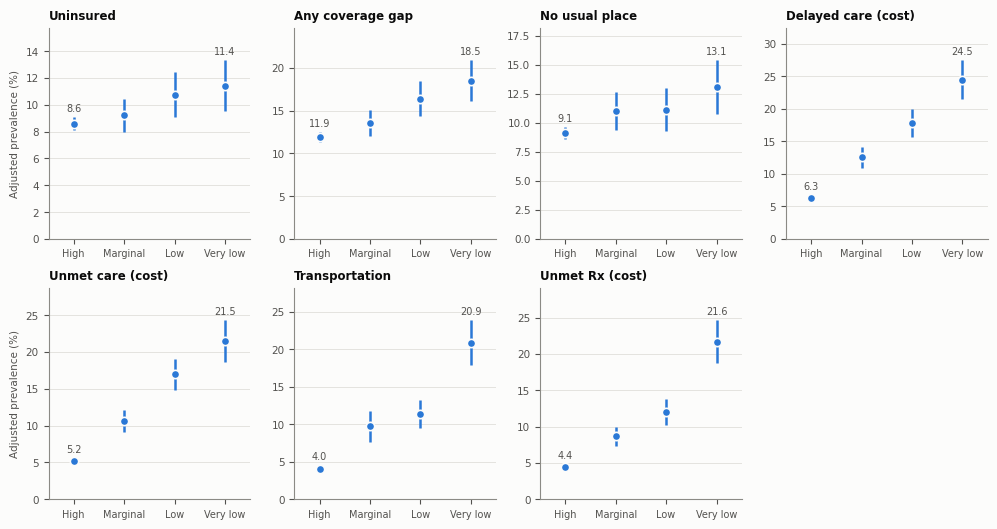

In [9]:
MVARS = ["FDSCAT4_A", "POV_CAT", "AGE_CAT", "PHSTAT_A"]
margins = {v: {k: svy_marginal(ds, k, 1, v, fit=fits[k]) for k in ORDER} for v in MVARS}
mrows = []
for v in MVARS:
    for k in ORDER:
        m = margins[v][k].copy(); m.insert(0, "outcome", k); mrows.append(m)
AM = pd.concat(mrows); AM.to_csv("results/adjusted_prevalence.csv", index=False)
plots.prev_panels(margins["FDSCAT4_A"], "FDSCAT4_A", SHORT, suptitle="Adjusted prevalence by food-security category (other covariates held at the sample distribution)",
                  outfile="figures/fig5_adjusted_prevalence_food_security.png"); plt.show()

In [10]:
def pp(x): return f"{100*x:.1f}"
picks = [("FDSCAT4_A", 4, "Very low vs High food security"), ("POV_CAT", 3, ">5 vs <2 FPL"), ("AGE_CAT", 4, "65+ vs 50-64"), ("PHSTAT_A", 5, "Poor vs Very good health")]
tab = {}
for v, lev, lab in picks:
    tab[lab] = [ (lambda r: f"{pp(r.rd)} ({pp(r.rd_lo)} to {pp(r.rd_hi)})")(margins[v][k].query("level==@lev").iloc[0]) for k in ORDER ]
display(Markdown("**Adjusted risk difference, percentage points (95% CI)**"))
display(pd.DataFrame(tab, index=[SHORT[k] for k in ORDER]))

**Adjusted risk difference, percentage points (95% CI)**

,Very low vs High food security,>5 vs <2 FPL,65+ vs 50-64,Poor vs Very good health
Uninsured,2.8 (0.9 to 4.8),-7.5 (-8.9 to -6.2),-7.4 (-8.3 to -6.5),-3.5 (-5.6 to -1.4)
Any coverage gap,6.6 (4.1 to 9.0),-9.3 (-10.9 to -7.8),-10.0 (-11.0 to -9.0),-1.3 (-4.2 to 1.7)
No usual place,4.0 (1.6 to 6.3),-3.0 (-4.3 to -1.7),-3.8 (-4.6 to -2.9),-3.1 (-5.6 to -0.7)
Delayed care (cost),18.1 (15.1 to 21.2),-2.4 (-3.5 to -1.2),-6.6 (-7.5 to -5.8),10.1 (6.8 to 13.5)
Unmet care (cost),16.3 (13.4 to 19.2),-2.3 (-3.4 to -1.2),-5.8 (-6.5 to -5.0),9.4 (6.5 to 12.2)
Transportation,16.8 (13.8 to 19.9),-3.6 (-4.8 to -2.4),-0.4 (-1.2 to 0.4),5.5 (3.3 to 7.7)
Unmet Rx (cost),17.2 (14.2 to 20.2),-1.9 (-3.0 to -0.9),-3.0 (-3.8 to -2.1),8.3 (5.8 to 10.8)


## 6 · Sensitivity analyses

**(a) Insurance status as an added covariate** (for outcomes other than the insurance outcomes themselves). Insurance may confound or mediate the other determinants, so this shows how much the ORs move.

In [11]:
P2 = PREDICTORS + ["INS_CAT"]
adj_ins, srows = {}, []
for k in ["NOUSUAL"] + BAR_OUT:
    r, i = svy_logit(ds, k, 1, predictors=P2, refs=REFS)
    r = plots._clean(r); adj_ins[k] = r
    a = r[r["var"] != "INS_CAT"].reset_index(drop=True); b = prim[k].reset_index(drop=True)
    dl = np.log(a.OR.values) - np.log(b.OR.values)
    ins = r[r["var"] == "INS_CAT"].iloc[0]
    fs = lambda x: x[(x["var"] == "FDSCAT4_A") & (x.level == 4)].iloc[0]
    srows.append({"outcome": SHORT[k], "n": i["n"], "max |dlogOR|": np.abs(dl).max(), "p<.05 changed": int(((a.p < .05) != (b.p < .05)).sum()),
                  "uninsured OR (95% CI)": f"{ins.OR:.2f} ({ins.lo:.2f}-{ins.hi:.2f})",
                  "very-low food sec. OR primary": f"{fs(b).OR:.2f}", "... + insurance": f"{fs(a).OR:.2f}"})
SA = pd.DataFrame(srows).set_index("outcome"); SA.to_csv("results/sens_a_insurance_covariate.csv"); display(SA)
long_a = pd.concat([adj_ins[k].assign(outcome=k) for k in adj_ins]); long_a.to_csv("results/sens_a_insurance_covariate_long.csv", index=False)

,n,max |dlogOR|,p<.05 changed,uninsured OR (95% CI),very-low food sec. OR primary,... + insurance
outcome,,,,,,
No usual place,30988,0.289,6,4.56 (3.96-5.26),1.56,1.45
Delayed care (cost),31002,0.344,4,4.75 (4.09-5.52),5.28,5.32
Unmet care (cost),31005,0.335,5,4.82 (4.10-5.67),5.47,5.52
Transportation,30953,0.033,1,1.25 (1.02-1.54),6.70,6.67
Unmet Rx (cost),30997,0.156,1,2.39 (2.00-2.86),6.46,6.32


**(b) Multiple imputation of income.** The public-use `RATCAT_A` equals imputation 1 of the ten NCHS income imputations, so the thesis analysis treated one draw as the observed value. Here each model is fit on all ten draws and pooled with Rubin's rules (Barnard-Rubin df).

In [12]:
ia = pd.read_csv(zipfile.ZipFile(DATA_DIR / "adultinc24csv.zip").open("adultinc24.csv"))
imp = {m: g.set_index("HHX")["RATCAT_A"] for m, g in ia.groupby("IMPNUM_A")}
flag = ia[ia.IMPNUM_A == 1].set_index("HHX")["IMPINCFLG_A"]
imp_share = svy_prop(ds, (ds.HHX.map(flag) > 0).astype(float))
print(f"Adults with imputed family income: {100*imp_share['p']:.1f}% weighted  ({int((ds.HHX.map(flag) > 0).sum()):,} unweighted); imputations: {sorted(imp)}")
def pov_cat(r): return np.select([r.between(1, 7), r.between(8, 13), r == 14], [1.0, 2.0, 3.0], default=np.nan)
assert (pov_cat(ds.HHX.map(imp[1])) == ds.POV_CAT.values).all(), "imputation 1 should reproduce RATCAT_A"
mi, mrows = {}, []
for k in ORDER:
    fl = []
    for m in range(1, 11):
        dm = ds.copy(); dm["POV_CAT"] = pov_cat(dm.HHX.map(imp[m]))
        r, i = svy_logit(dm, k, 1); fl.append(r)
    mi[k] = plots._clean(pool_mi(fl, i["df"]))
    a, b = mi[k].reset_index(drop=True), prim[k].reset_index(drop=True)
    pv = a["var"] == "POV_CAT"
    mrows.append({"outcome": SHORT[k], "max |dlogOR| (all)": np.abs(np.log(a.OR) - np.log(b.OR)).max(), "p<.05 changed": int(((a.p < .05) != (b.p < .05)).sum()),
                  "POV SE ratio (MI / single)": float(np.mean(a.se[pv] / b.se[pv])), "max FMI (POV rows)": float(a.fmi[pv].max()),
                  ">5FPL OR primary": f"{b.OR[pv].iloc[1]:.2f}", ">5FPL OR MI": f"{a.OR[pv].iloc[1]:.2f}"})
SB = pd.DataFrame(mrows).set_index("outcome"); SB.to_csv("results/sens_b_multiple_imputation.csv"); display(SB)
pd.concat([mi[k].assign(outcome=k) for k in mi]).to_csv("results/sens_b_multiple_imputation_long.csv", index=False)

Adults with imputed family income: 24.5% weighted  (7,474 unweighted); imputations: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


,max |dlogOR| (all),p<.05 changed,POV SE ratio (MI / single),max FMI (POV rows),>5FPL OR primary,>5FPL OR MI
outcome,,,,,,
Uninsured,0.024,0,1.030,0.124,0.30,0.31
Any coverage gap,0.044,0,1.032,0.115,0.35,0.36
No usual place,0.026,0,1.031,0.094,0.68,0.68
Delayed care (cost),0.052,0,1.046,0.146,0.68,0.71
Unmet care (cost),0.038,0,1.024,0.095,0.64,0.67
Transportation,0.014,0,1.035,0.062,0.50,0.51
Unmet Rx (cost),0.016,0,1.038,0.048,0.67,0.68


**(c) Unweighted models** (shows how much the survey weights matter) and **(d) collinearity** among the dummy-coded predictors (weighted VIF).

In [13]:
crows = []
for k in ORDER:
    dd = ds.dropna(subset=[k] + PREDICTORS); X, meta = design_matrix(dd)
    res = sm.GLM(dd[k].values, X.values, family=sm.families.Binomial()).fit()
    b = prim[k].reset_index(drop=True)
    uo, up = np.exp(np.asarray(res.params))[1:], np.asarray(res.pvalues)[1:]
    crows.append({"outcome": SHORT[k], "corr(logOR weighted, unweighted)": np.corrcoef(np.log(b.OR), np.log(uo))[0, 1],
                  "max |dlogOR|": np.abs(np.log(b.OR) - np.log(uo)).max(), "p<.05 changed": int(((b.p < .05) != (up < .05)).sum())})
SC = pd.DataFrame(crows).set_index("outcome"); SC.to_csv("results/sens_c_unweighted.csv"); display(SC)

dd = ds.dropna(subset=PREDICTORS); X, meta = design_matrix(dd); Xv = X.drop(columns="const"); w = dd.WTFA_A.values
Xc = Xv.values - (Xv.values * w[:, None]).sum(0) / w.sum()
cov = (Xc * w[:, None]).T @ Xc / w.sum(); R = cov / np.outer(np.sqrt(np.diag(cov)), np.sqrt(np.diag(cov)))
vif = pd.Series(np.diag(np.linalg.inv(R)), index=Xv.columns).sort_values(ascending=False)
print("Weighted VIF, top 8 (all < 5 means no worrying collinearity):"); display(vif.head(8).to_frame("VIF")); vif.to_csv("results/sens_d_vif.csv")

,"corr(logOR weighted, unweighted)",max |dlogOR|,p<.05 changed
outcome,,,
Uninsured,0.994,0.283,4
Any coverage gap,0.989,0.345,2
No usual place,0.989,0.133,4
Delayed care (cost),0.996,0.186,2
Unmet care (cost),0.997,0.128,2
Transportation,0.985,0.235,5
Unmet Rx (cost),0.994,0.154,4


Weighted VIF, top 8 (all < 5 means no worrying collinearity):


,VIF
EDU_CAT=4,3.605
EDU_CAT=3,3.031
EDU_CAT=2,2.801
POV_CAT=3,2.304
POV_CAT=2,1.800
AGE_CAT=1,1.750
AGE_CAT=2,1.579
AGE_CAT=4,1.568


## 7 · Numbers for the manuscript

In [14]:
def orci(k, var, lev):
    r = prim[k].query("var==@var and level==@lev").iloc[0]
    return {"OR": r.OR, "lo": r.lo, "hi": r.hi, "p": r.p, "q": r.q_BH}
key = {
  "n_adults": int(len(ds)), "n_complete_predictors": int(len(cc)), "weighted_population_millions": float(ds.WTFA_A.sum() / 1e6),
  "n_strata": int(ds.PSTRAT.nunique()), "n_psu": int(ds.groupby(["PSTRAT", "PPSU"]).ngroups), "df": int(fits["UNINS"][1]["df"]),
  "share_income_imputed_weighted_pct": float(100 * imp_share["p"]),
  "outcomes": {k: {"label": SHORT[k], "n_model": fits[k][1]["n"], "events_model": fits[k][1]["n_events"],
                   "prev_pct": 100 * overall[k]["p"], "prev_lo": 100 * overall[k]["lo"], "prev_hi": 100 * overall[k]["hi"], "n_prev": overall[k]["n"],
                   "prev_cc_pct": 100 * overall_cc[k]["p"],
                   "n_sig_p05": int((prim[k].p < .05).sum()), "n_sig_q05": int((prim[k].q_BH < .05).sum())} for k in ORDER},
  "headline_ORs": {k: {"very_low_food_security": orci(k, "FDSCAT4_A", 4), "poor_health": orci(k, "PHSTAT_A", 5), "income_gt5fpl": orci(k, "POV_CAT", 3),
                       "age65plus": orci(k, "AGE_CAT", 4), "black": orci(k, "RACE_CAT", 3), "asian": orci(k, "RACE_CAT", 4),
                       "hispanic": orci(k, "RACE_CAT", 1), "northeast": orci(k, "REGION", 1), "female": orci(k, "SEX_A", 2)} for k in ORDER},
}
json.dump(key, open("results/key_numbers.json", "w"), indent=1, default=float)
print(json.dumps({k: key[k] for k in ["n_adults", "n_complete_predictors", "weighted_population_millions", "n_strata", "n_psu", "df", "share_income_imputed_weighted_pct"]}, indent=1))
print("results written:", sorted(__import__("os").listdir("results")))

{
 "n_adults": 32629,
 "n_complete_predictors": 31076,
 "weighted_population_millions": 259.65393547099995,
 "n_strata": 52,
 "n_psu": 662,
 "df": 610,
 "share_income_imputed_weighted_pct": 24.495559104708317
}
results written: ['adjusted_prevalence.csv', 'key_numbers.json', 'primary_models_long.csv', 'sens_a_insurance_covariate.csv', 'sens_a_insurance_covariate_long.csv', 'sens_b_multiple_imputation.csv', 'sens_b_multiple_imputation_long.csv', 'sens_c_unweighted.csv', 'sens_d_vif.csv', 'table1_descriptives_long.csv', 'table2_adjusted_ORs.csv']
